# Global Wheat Production Analysis

## 1. Project Overview

This project explores global wheat production patterns
across countries from 2010 to 2024 using data from FAOSTAT.

The analysis focuses on understanding production trends,
identifying major wheat-producing countries, and comparing
agricultural production across different regions.

### Project Objectives

- Analyze global wheat production trends over time.
- Identify the world's leading wheat-producing countries.
- Compare production levels across countries.
- Examine annual changes in wheat production.
- Identify significant patterns and key insights.

### Data Source

- Source: FAOSTAT
- Dataset: Crops and Livestock Products
- Commodity: Wheat
- Element: Production
- Period: 2010–2024
- Geographic Coverage: Global

## 2. Environment Setup

This section prepares the Python environment by importing the libraries required for data retrieval, manipulation, and visualization.

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pydata_google_auth

from google.cloud import bigquery

print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

print("All libraries imported successfully!")

Pandas: 2.2.2
NumPy: 1.26.4
All libraries imported successfully!


## 3. Connect to Google BigQuery

Google BigQuery is used as the primary data warehouse for this project.

In this section, we authenticate with Google Cloud and establish a connection to the BigQuery project.

In [81]:
SCOPES = ["https://www.googleapis.com/auth/bigquery"]

credentials = pydata_google_auth.get_user_credentials(
    scopes=SCOPES
)

client = bigquery.Client(
    credentials=credentials,
    project="global-wheat-production"
)

print("BigQuery connection established successfully!")

BigQuery connection established successfully!


## 4. Load the Wheat Production Data

The wheat production dataset is retrieved from Google BigQuery using SQL.

The query selects the relevant columns and applies initial filters to focus on wheat production between 2010 and 2024.

The resulting dataset is loaded into a Pandas DataFrame for further analysis.

In [83]:
query = """
SELECT
    Year AS year,
    Area AS area,
    Item AS crop,
    Element AS element,
    Unit AS unit,
    Value AS production_value

FROM
    `global-wheat-production.global_wheat.wheat_production_clean`

WHERE
    Item = 'Wheat'
    AND Element = 'Production'
    AND Year BETWEEN 2010 AND 2024
    
ORDER BY
    Year,
    Area
"""

df = client.query(query).to_dataframe()

print("Data loaded successfully!")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Data loaded successfully!
Rows: 1,888
Columns: 6


## 5. Dataset Overview & Profiling

Before performing detailed analysis, we examine the structure and general characteristics of the dataset.

This initial exploration helps us understand the available information and identify potential issues before data cleaning.

### 5.1 Dataset Structure

In [86]:
print(f"Total records: {len(df):,}")
print(f"Total columns: {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Total records: 1,888
Total columns: 6
Memory usage: 0.43 MB


### 5.2 Variable Overview

In [88]:
variable_overview = pd.DataFrame({
    "Variable": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

display(variable_overview)

,Variable,Data Type,Missing Values,Unique Values
0,year,Int64,0,15
1,area,object,0,127
2,crop,object,0,1
3,element,object,0,1
4,unit,object,0,1
5,production_value,float64,15,1759


### 5.3 Temporal and Geographic Coverage

In [90]:
print(f"Year range: {df['year'].min()} - {df['year'].max()}")
print(f"Number of reporting areas: {df['area'].nunique()}")

print("\nRecords per year:")
display(df.groupby("year").size().to_frame("Record Count"))

Year range: 2010 - 2024
Number of reporting areas: 127

Records per year:


,Record Count
year,
2010,126
2011,126
2012,126
2013,126
2014,126
2015,126
2016,126
2017,126
2018,126


### 5.4 Production Units and Data Characteristics

In [92]:
print("Production units:")
display(df["unit"].value_counts())

print("\nProduction statistics:")
display(df["production_value"].describe())

Production units:


unit
t    1888
Name: count, dtype: int64


Production statistics:


count    1.873000e+03
mean     7.008075e+06
std      2.056175e+07
min      0.000000e+00
25%      2.092100e+04
50%      4.903200e+05
75%      3.476027e+06
max      1.401050e+08
Name: production_value, dtype: float64

### 5.5 Sample Records

In [94]:
display(df.sample(min(10, len(df)), random_state=42))

,year,area,crop,element,unit,production_value
1185,2019,Israel,Wheat,Production,t,84750.00
1054,2018,Hungary,Wheat,Production,t,5258430.00
1743,2023,Sweden,Wheat,Production,t,2768200.00
1512,2022,Afghanistan,Wheat,Production,t,3802895.00
1460,2021,Mozambique,Wheat,Production,t,15000.00
1726,2023,Peru,Wheat,Production,t,194004.08
596,2014,Qatar,Wheat,Production,t,5.00
1450,2021,Luxembourg,Wheat,Production,t,76140.00
859,2016,South Africa,Wheat,Production,t,1910000.00
212,2011,Pakistan,Wheat,Production,t,25213800.00


### 5.6 Analytical Scope and Data Structure

The dataset contains annual wheat production records
reported by countries and other geographic areas.

Each observation represents the recorded wheat production
for a specific reporting area and year.

The analysis focuses on:

- Commodity: Wheat
- Measurement: Production
- Time period: 2010–2024
- Geographic scope: Global
- Measurement unit: Tonnes

The primary analytical dimensions are time and geography,
while production quantity is the main numerical variable.

This structure will guide the subsequent data quality
assessment and exploratory analysis.

## 6. Data Quality Assessment

This section evaluates the completeness, consistency, and reliability of the dataset before conducting further analysis.

The assessment focuses on missing values, duplicate records, production value validity, and temporal and geographic coverage.

### 6.1 Missing Values Assessment

Missing values can affect the accuracy and reliability of statistical analysis.

This step identifies missing observations across all variables and evaluates the overall completeness of the dataset.

In [98]:
missing_production = df[
    df["production_value"].isna()
]

display(
    missing_production[
        ["year", "area", "crop", "element", "unit"]
    ].sort_values(["area", "year"])
)

,year,area,crop,element,unit
116,2010,United Arab Emirates,Wheat,Production,t
242,2011,United Arab Emirates,Wheat,Production,t
368,2012,United Arab Emirates,Wheat,Production,t
494,2013,United Arab Emirates,Wheat,Production,t
620,2014,United Arab Emirates,Wheat,Production,t
746,2015,United Arab Emirates,Wheat,Production,t
872,2016,United Arab Emirates,Wheat,Production,t
998,2017,United Arab Emirates,Wheat,Production,t
1124,2018,United Arab Emirates,Wheat,Production,t
1250,2019,United Arab Emirates,Wheat,Production,t


In [99]:
display(
    missing_production["area"].value_counts()
)

area
United Arab Emirates    15
Name: count, dtype: int64

#### Missing Values – Key Observation

A total of 15 missing production values were identified.

All missing observations belong to the United Arab Emirates,
covering the entire analysis period from 2010 to 2024.

This indicates a systematic pattern of missing data rather
than randomly distributed missing observations.

The missing values will be retained during the assessment
and will not be replaced with zero, as missing production
data does not necessarily indicate zero production.

### 6.2 Duplicate Records Assessment

Duplicate records may lead to inaccurate production totals and misleading statistical results.

This step identifies both exact duplicate rows and repeated observations based on the dataset's analytical dimensions.

In [102]:
# Check for exact duplicate rows
exact_duplicates = df.duplicated().sum()

print(f"Exact duplicate records: {exact_duplicates:,}")

Exact duplicate records: 0


In [103]:
# Check duplicate analytical observations
key_columns = [
    "year",
    "area",
    "crop",
    "element"
]

duplicate_observations = df[
    df.duplicated(
        subset=key_columns,
        keep=False
    )
].sort_values(key_columns)

print(
    f"Records involved in repeated observations: "
    f"{len(duplicate_observations):,}"
)

display(duplicate_observations.head(20))

Records involved in repeated observations: 0


,year,area,crop,element,unit,production_value


No exact duplicate records were identified in the dataset.
Each record is unique across all available columns.

### 6.3 Zero and Negative Production Values

Production values should be examined to identify zero and negative observations.

Zero values may represent valid records where no production was reported, while negative production values require further investigation.

In [106]:
zero_production = df[
    df["production_value"] == 0
]

negative_production = df[
    df["production_value"] < 0
]

print(f"Zero production records: {len(zero_production):,}")
print(f"Negative production records: {len(negative_production):,}")

Zero production records: 19
Negative production records: 0


In [107]:
display(
    zero_production[
        ["year", "area", "production_value", "unit"]
    ].sort_values(
        ["area", "year"]
    ) 
)

,year,area,production_value,unit
15,2010,Botswana,0.0,t
141,2011,Botswana,0.0,t
267,2012,Botswana,0.0,t
393,2013,Botswana,0.0,t
519,2014,Botswana,0.0,t
645,2015,Botswana,0.0,t
771,2016,Botswana,0.0,t
897,2017,Botswana,0.0,t
1076,2018,Malta,0.0,t
1202,2019,Malta,0.0,t


In [108]:
display(
    negative_production[
        ["year", "area", "production_value", "unit"]
    ]
)

,year,area,production_value,unit


#### Key Findings

- 19 zero-production records identified across four reporting areas.
- No negative production values found.
- Zero values retained for further analysis.

### 6.4 Temporal and Geographic Completeness

This step examines the distribution of observations across years and reporting areas.

The objective is to identify changes in annual record counts and potential gaps in geographic reporting coverage.

In [111]:
annual_coverage = (
    df.groupby("year")
    .agg(
        Record_Count=("area", "size"),
        Reporting_Areas=("area", "nunique")
    )
    .reset_index()
)

display(annual_coverage)

,year,Record_Count,Reporting_Areas
0,2010,126,126
1,2011,126,126
2,2012,126,126
3,2013,126,126
4,2014,126,126
5,2015,126,126
6,2016,126,126
7,2017,126,126
8,2018,126,126
9,2019,126,126


In [112]:
recent_years = df[
    df["year"].isin([2023, 2024])
]

recent_coverage = (
    recent_years.groupby("year")["area"]
    .apply(lambda x: sorted(set(x)))
)

print("Reporting areas in 2023 and 2024:")

for year, areas in recent_coverage.items():
    print(f"\n{year}:")
    print(areas)

Reporting areas in 2023 and 2024:

2023:
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belgium', 'Bhutan', 'Bolivia (Plurinational State of)', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Canada', 'Chad', 'Chile', 'China', 'China, Taiwan Province of', 'China, mainland', 'Colombia', 'Croatia', 'Cyprus', 'Czechia', "Democratic People's Republic of Korea", 'Democratic Republic of the Congo', 'Denmark', 'Ecuador', 'Egypt', 'Eritrea', 'Estonia', 'Eswatini', 'Ethiopia', 'Finland', 'France', 'Georgia', 'Germany', 'Greece', 'Guatemala', 'Honduras', 'Hungary', 'India', 'Iran (Islamic Republic of)', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kuwait', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Lesotho', 'Libya', 'Lithuania', 'Luxembourg', 'Madagascar', 'Malawi', 'Mali', 'Malta', 'Mauritania', 'Mexico', 'Mongolia', 'Montenegro', 'Morocco', 

#### Key Findings

- Annual records remained consistent at 126 from 2010 to 2022.
- Record counts decreased to 125 in 2023 and 2024.
- The reporting areas were identical in 2023 and 2024.
- The United Arab Emirates was present in both years despite having missing production values.

### 6.5 Data Type and Value Consistency

This step verifies that the variables use appropriate data types and that categorical fields contain consistent values.

Particular attention is given to the year, production value, commodity, measurement element, and production unit.

In [115]:
print("Data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nUnique crop values:")
display(df["crop"].value_counts(dropna=False))

print("\nUnique element values:")
display(df["element"].value_counts(dropna=False))

print("\nProduction units:")
display(df["unit"].value_counts(dropna=False))

print("Year column numeric:", 
      pd.api.types.is_numeric_dtype(df["year"]))

print("Production column numeric:", 
      pd.api.types.is_numeric_dtype(df["production_value"]))

Data types:


,Data Type
year,Int64
area,object
crop,object
element,object
unit,object
production_value,float64



Unique crop values:


crop
Wheat    1888
Name: count, dtype: int64


Unique element values:


element
Production    1888
Name: count, dtype: int64


Production units:


unit
t    1888
Name: count, dtype: int64

Year column numeric: True
Production column numeric: True


#### Key Findings

- Year and production columns have appropriate numeric data types.
- All records consistently represent wheat production.
- Production values use a consistent unit (tonnes).
- No data type or categorical inconsistencies were identified.

In [117]:
# Prepare analysis dataset

excluded_areas = [
    "China, mainland",
    "China, Taiwan Province of"
]

analysis_df = df[
    ~df["area"].isin(excluded_areas)
].copy()

print("Analysis dataset prepared successfully!")
print(f"Original records: {len(df):,}")
print(f"Analysis records: {len(analysis_df):,}")
print(f"Excluded records: {len(df) - len(analysis_df):,}")

Analysis dataset prepared successfully!
Original records: 1,888
Analysis records: 1,858
Excluded records: 30


## 7. Exploratory Data Analysis

This section explores global wheat production patterns from 2010 to 2024 through statistical summaries and visualizations. The analysis focuses on production trends, annual changes, and differences across countries.

### 7.1 Annual Production Trend Chart
This section examines year-over-year (YoY) changes in global wheat production to identify periods of significant growth and decline between 2010 and 2024.

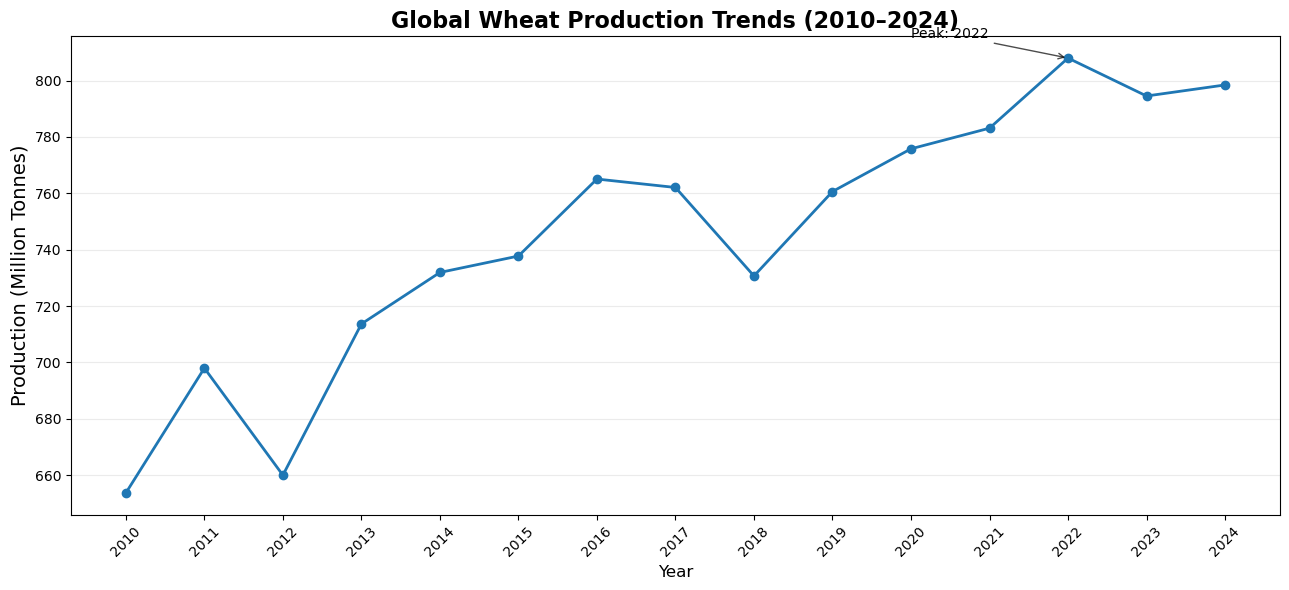

In [119]:
# Calculate annual global wheat production

annual_production = (
    analysis_df.groupby("year")["production_value"]
    .sum()
    .reset_index()
)

annual_production.columns = [
    "year",
    "total_production"
]

# Calculate year-over-year percentage change

annual_production["yoy_change_pct"] = (
    annual_production["total_production"]
    .pct_change() * 100
)

plt.figure(figsize=(13, 6))

plt.plot(
    annual_production["year"],
    annual_production["total_production"] / 1_000_000,
    marker="o",
    linewidth=2,
    markersize=6
)

plt.title(
    "Global Wheat Production Trends (2010–2024)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Production (Million Tonnes)", fontsize=14)

plt.xticks(annual_production["year"], rotation=45)

plt.grid(axis="y", alpha=0.25)

plt.annotate(
    "Peak: 2022",
    xy=(2022, 808),
    xytext=(2020, 815),
    arrowprops=dict(arrowstyle="->", alpha=0.7),
    fontsize=10
)

plt.tight_layout()
plt.show()

- Global wheat production increased by approximately 22.1% between 2010 and 2024.
- Production reached its highest level in 2022, at approximately 808.0 million tonnes.
- Production declined in 2023 and partially recovered in 2024.

#### Note

Annual totals represent reported production. Missing production values for the United Arab Emirates are excluded from the calculations.

### 7.2 Annual Production Growth Analysis

This section examines year-over-year (yoy) changes in global wheat production to identify periods of significant growth and decline. 

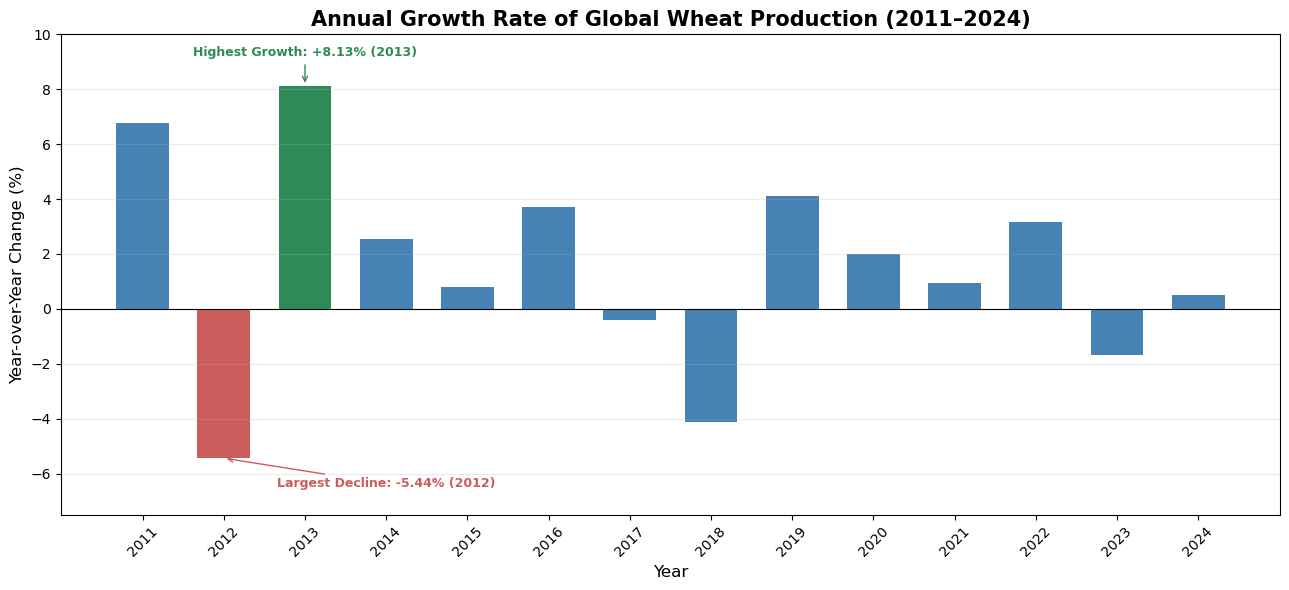

In [122]:
growth_data = annual_production.dropna(
    subset=["yoy_change_pct"]
).copy()
max_growth = growth_data["yoy_change_pct"].idxmax()
min_growth = growth_data["yoy_change_pct"].idxmin()
colors = [
    "seagreen" if idx == max_growth
    else "indianred" if idx == min_growth
    else "steelblue"
    for idx in growth_data.index
]
fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(
    growth_data["year"],
    growth_data["yoy_change_pct"],
    color=colors,
    width=0.65
)
ax.axhline(y=0, color="black", linewidth=0.8)

ax.annotate(
    "Highest Growth: +8.13% (2013)",
    xy=(2013, 8.13),
    xytext=(2013, 9.2),
    ha="center",
    fontsize=9,
    fontweight="bold",
    color="seagreen",
    arrowprops=dict(arrowstyle="->", color="seagreen")
)

# Highlight the largest decline
ax.annotate(
    "Largest Decline: -5.44% (2012)",
    xy=(2012, -5.44),
    xytext=(2014, -6.5),
    ha="center",
    fontsize=9,
    fontweight="bold",
    color="indianred",
    arrowprops=dict(arrowstyle="->", color="indianred")
)

ax.set_title(
    "Annual Growth Rate of Global Wheat Production (2011–2024)",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Year", fontsize=12)

ax.set_ylabel("Year-over-Year Change (%)", fontsize=12)

ax.set_xticks(growth_data["year"])

ax.tick_params(axis="x", rotation=45)

ax.set_ylim(-7.5, 10)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#### Annual Growth Observations

- The highest annual growth occurred in 2013 (+8.13%).
- The largest annual decline was recorded in 2012 (-5.44%).
- Production growth fluctuated throughout the analyzed period.
- In 2024, production increased by approximately 0.49% following the decline in 2023.

### 7.3 Global Wheat Production by Country

This section compares wheat production across reporting areas to identify the world's largest wheat producers and examine their contribution to reported global production.

### 7.3.1 Production Distribution by Range

This section categorizes wheat production records into predefined production ranges to examine how production levels are distributed across reporting areas.

In [125]:
# Define wheat production ranges (million tonnes)

production_ranges = [
    "0–1 million",
    "1–5 million",
    "5–10 million",
    "10–20 million",
    "20+ million"
]
production_categories = pd.cut(
    analysis_df["production_value"] / 1_000_000,
    bins=[0, 1, 5, 10, 20, float("inf")],
    labels=production_ranges,
    right=False,
    include_lowest=True
)

production_distribution = (
    production_categories
    .value_counts(sort=False)
    .reset_index()
)

production_distribution.columns = [
    "production_range",
    "number_of_records"
]

display(production_distribution)

,production_range,number_of_records
0,0–1 million,1071
1,1–5 million,394
2,5–10 million,146
3,10–20 million,75
4,20+ million,157


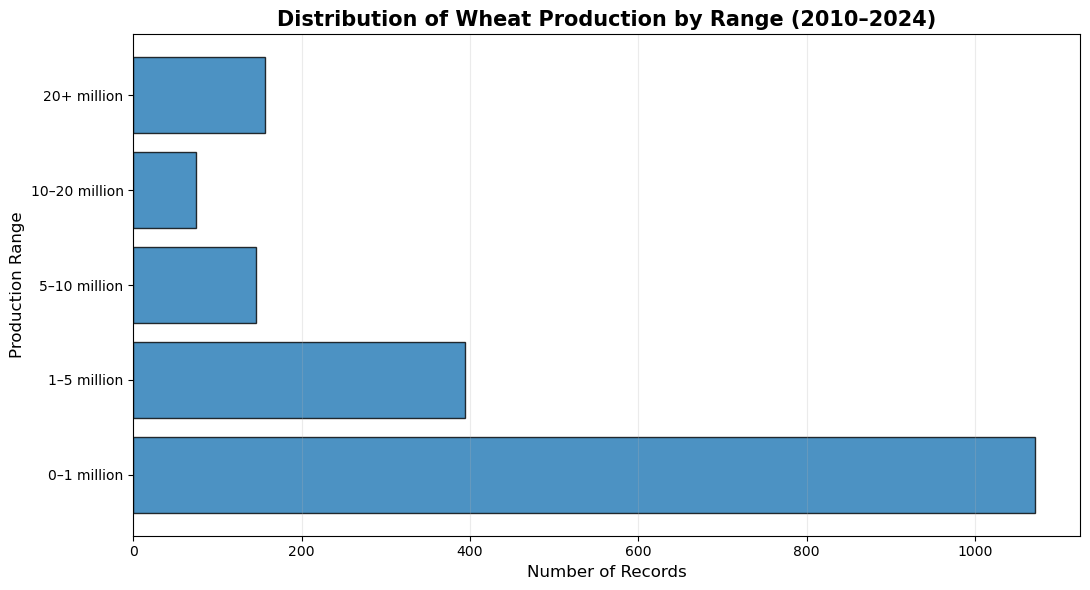

In [126]:
plt.figure(figsize=(11, 6))

plt.barh(
    production_distribution["production_range"],
    production_distribution["number_of_records"],
    edgecolor="black",
    alpha=0.8
)

plt.title(
    "Distribution of Wheat Production by Range (2010–2024)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Records", fontsize=12)
plt.ylabel("Production Range", fontsize=12)

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

#### 7.3.2 Production Distribution Statistics

This analysis examines the statistical characteristics of wheat production values across reporting areas from 2010 to 2024. Key descriptive statistics are used to understand the central tendency, variability, and range of production.

In [128]:
production_statistics = (
    analysis_df["production_value"]
    .describe()
    .to_frame(name="Production (Tonnes)")
)

display(production_statistics.round(2))

,Production (Tonnes)
count,1.843000e+03
mean,6.062672e+06
std,1.744669e+07
min,0.000000e+00
25%,2.211250e+04
50%,4.903200e+05
75%,3.336815e+06
max,1.401050e+08


In [129]:
additional_metrics = pd.Series({
    "Skewness": analysis_df["production_value"].skew(),
    "Zero Production Records": (
        analysis_df["production_value"] == 0
    ).sum(),
    "Missing Production Records": (
        analysis_df["production_value"].isna()
    ).sum()
})

display(additional_metrics.to_frame("Value").round(2))

,Value
Skewness,5.01
Zero Production Records,19.00
Missing Production Records,15.00



- The mean production (7.01 million tonnes) is considerably higher than the median (0.49 million tonnes).
- Production values show substantial variability, with a standard deviation of 20.57 million tonnes.
- The distribution is strongly positively skewed (4.66), indicating that a relatively small number of high-production observations influence the overall distribution.
- Production values range from zero to approximately 140.11 million tonnes.

#### 7.3.3 Production Distribution by Year

This analysis compares the distribution of wheat production across reporting areas for each year between 2010 and 2024. Annual box plots are used to examine changes in median production, variability, and extreme values over time.

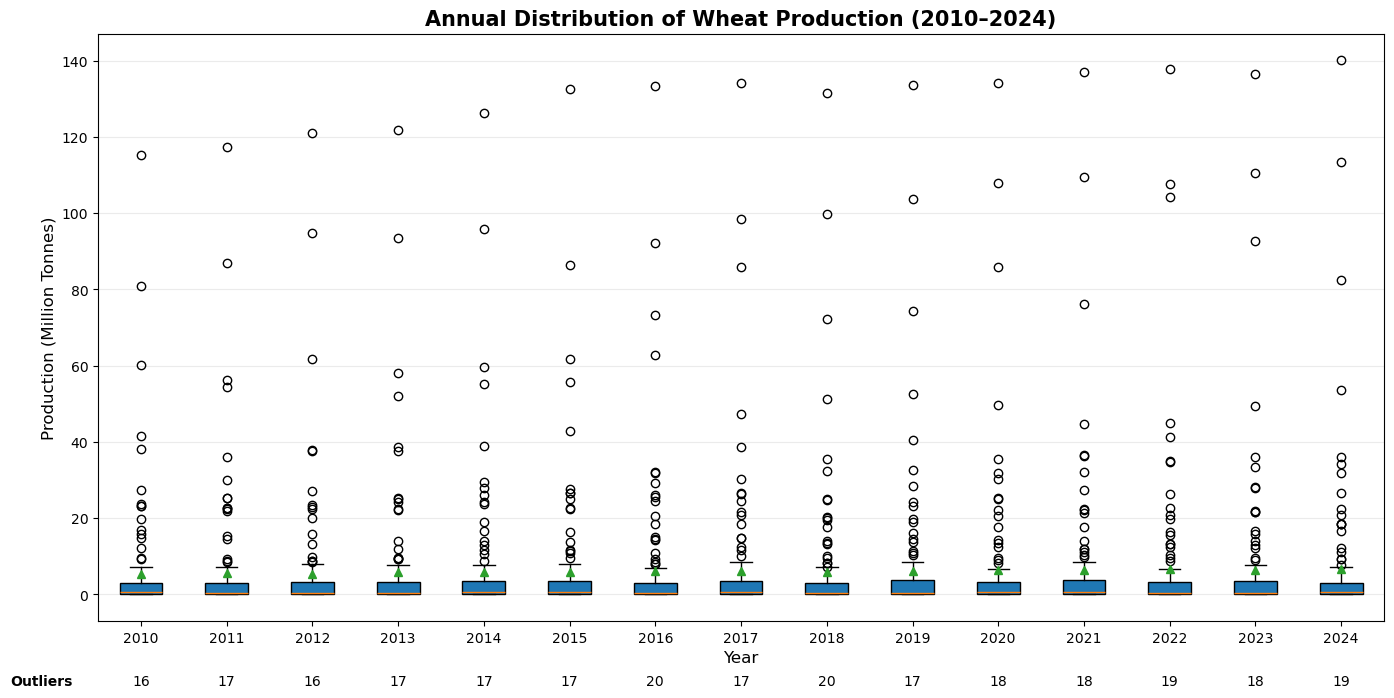

In [132]:
# Calculate outlier counts for each year
outlier_counts = []

# Prepare annual production data for boxplot

years = sorted(analysis_df["year"].unique())

yearly_production = [
    analysis_df.loc[
        analysis_df["year"] == year,
        "production_value"
    ].dropna().values / 1_000_000
    for year in years
]

fig, ax = plt.subplots(figsize=(14, 7))

boxplot = ax.boxplot(
    yearly_production,
    tick_labels=years,
    showmeans=True,
    showfliers=True,
    patch_artist=True
)

for values in yearly_production:
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = ((values < lower_bound) | (values > upper_bound)).sum()
    outlier_counts.append(count)

# Add outlier counts below each year
ax.set_xticks(range(1, len(years) + 1))
ax.set_xticklabels(years)

# Add outlier counts in a separate row
for i, count in enumerate(outlier_counts, start=1):
    ax.text(
        i, -0.09,
        str(count),
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=10
    )

ax.text(
    -0.02, -0.09,
    "Outliers",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    fontweight="bold"
)

plt.subplots_adjust(bottom=0.18)

ax.set_title(
    "Annual Distribution of Wheat Production (2010–2024)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Production (Million Tonnes)", fontsize=12)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#### Key Findings

- Wheat production values are strongly concentrated at relatively low levels across reporting areas.
- A small number of reporting areas consistently appear as statistical outliers due to their high production values.
- The overall distribution pattern remained relatively similar between 2010 and 2024.
- The number of outliers varied across years, ranging from 17 to 20.

## 8. Country-Level Analysis

This section examines wheat production across reporting areas between 2010 and 2024. It identifies the leading producers, compares production levels, and explores differences in production patterns across countries.

In [135]:
excluded_areas = [
    "China, mainland",
    "China, Taiwan Province of"
]

country_production = (
    df[~df["area"].isin(excluded_areas)]
    .groupby("area")
    .agg(
        total_production=(
            "production_value",
            lambda x: x.sum(min_count=1)
        )
    )
    .reset_index()
    .dropna(subset=["total_production"])
    .sort_values("total_production", ascending=False)
    .reset_index(drop=True)
)

top_10_producers = country_production.head(10).copy()
other_producers = country_production.iloc[10:].copy()

display(top_10_producers)

,area,total_production
0,China,1.952621e+09
1,India,1.481749e+09
2,Russian Federation,1.056541e+09
3,United States of America,8.017643e+08
4,France,5.404365e+08
5,Canada,4.601356e+08
6,Australia,4.078264e+08
7,Pakistan,3.879020e+08
8,Ukraine,3.550850e+08
9,Germany,3.468810e+08


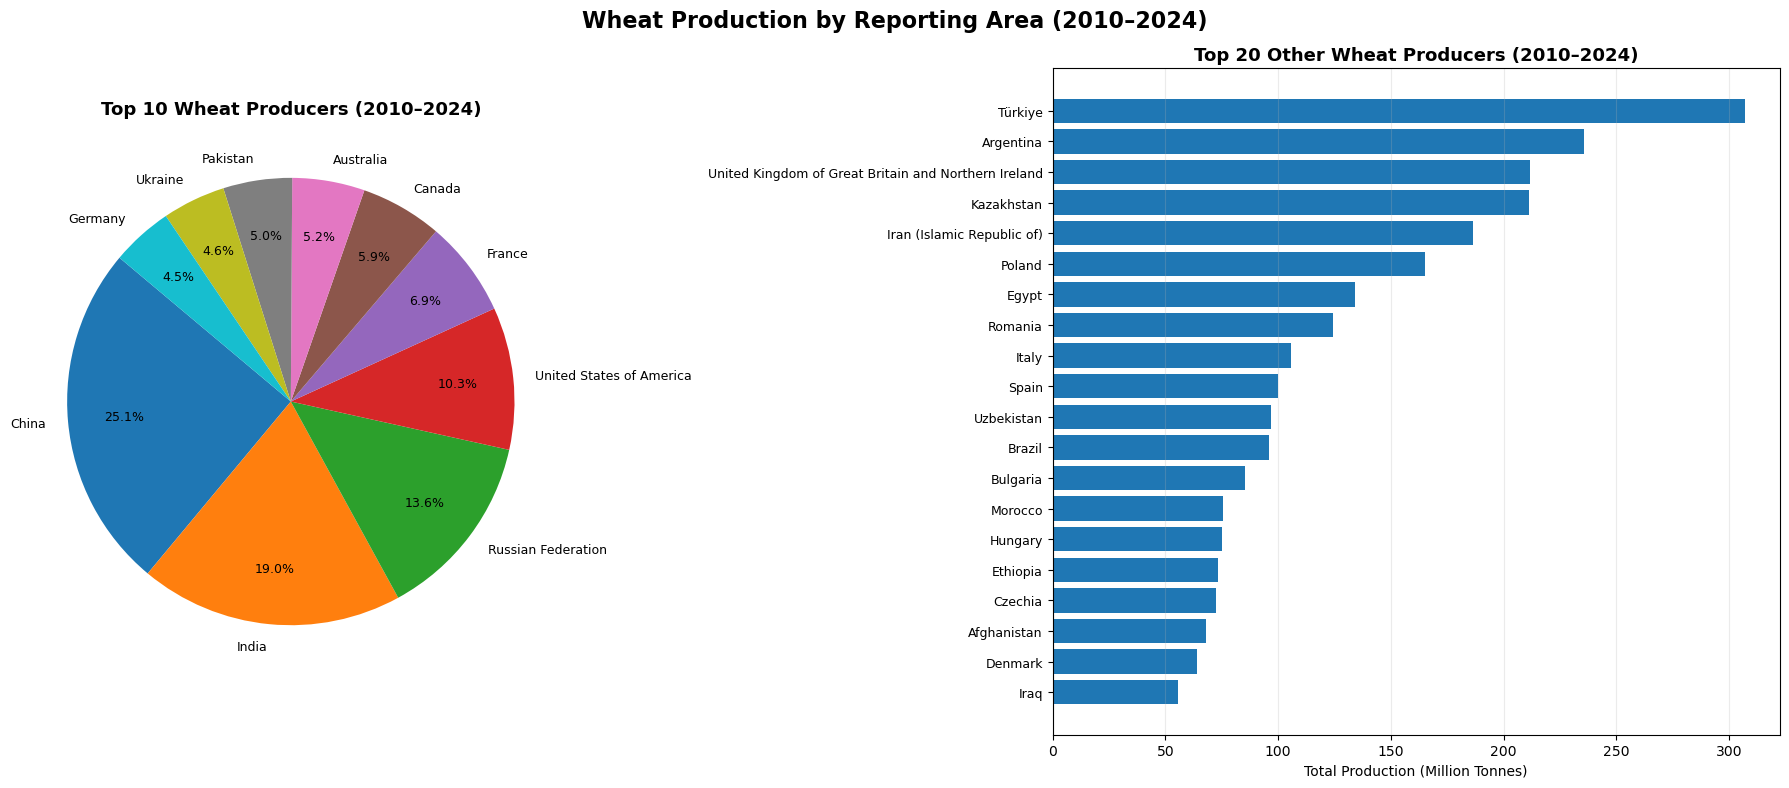

In [136]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8),
    gridspec_kw={"width_ratios": [1, 1.3]}
)

# Left: Top 10 Wheat Producers
axes[0].pie(
    top_10_producers["total_production"],
    labels=top_10_producers["area"],
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.75,
    textprops={"fontsize": 9}
)

axes[0].set_title(
    "Top 10 Wheat Producers (2010–2024)",
    fontsize=13,
    fontweight="bold"
)

# Right: Top 20 Other Producers
top_20_other = other_producers.head(20).sort_values(
    "total_production",
    ascending=True
)

axes[1].barh(
    top_20_other["area"],
    top_20_other["total_production"] / 1_000_000
)

axes[1].set_title(
    "Top 20 Other Wheat Producers (2010–2024)",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_xlabel("Total Production (Million Tonnes)")
axes[1].tick_params(axis="y", labelsize=9)
axes[1].grid(axis="x", alpha=0.25)

plt.suptitle(
    "Wheat Production by Reporting Area (2010–2024)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 8.2 Concentration of Global Wheat Production

This section examines how much of global wheat production is contributed by the largest producers. It compares the cumulative production shares of the 3, 5, and 10 largest reporting areas between 2010 and 2024.
#### 8.2.1 Calculate Production Concentration

In [138]:
# Calculate total production by country

country_production = (
    analysis_df.groupby("area")["production_value"]
    .sum()
    .reset_index()
    .rename(columns={"production_value": "total_production"})
    .sort_values("total_production", ascending=False)
)

# Calculate global production total

global_total = analysis_df["production_value"].sum()

print("Global total:", global_total)


concentration_data = pd.DataFrame({
    "producer_group": ["3 Largest Producers", "5 Largest Producers", "10 Largest Producers"],
    "global_share_pct": [
        country_production.head(3)["total_production"].sum() / global_total * 100,
        country_production.head(5)["total_production"].sum() / global_total * 100,
        country_production.head(10)["total_production"].sum() / global_total * 100
    ]
})

concentration_data["global_share_pct"] = (
    concentration_data["global_share_pct"].round(2)
)

display(concentration_data)

Global total: 11173503576.46


,producer_group,global_share_pct
0,3 Largest Producers,40.19
1,5 Largest Producers,52.20
2,10 Largest Producers,69.73


#### 8.2.2 Visualize Production Concentration

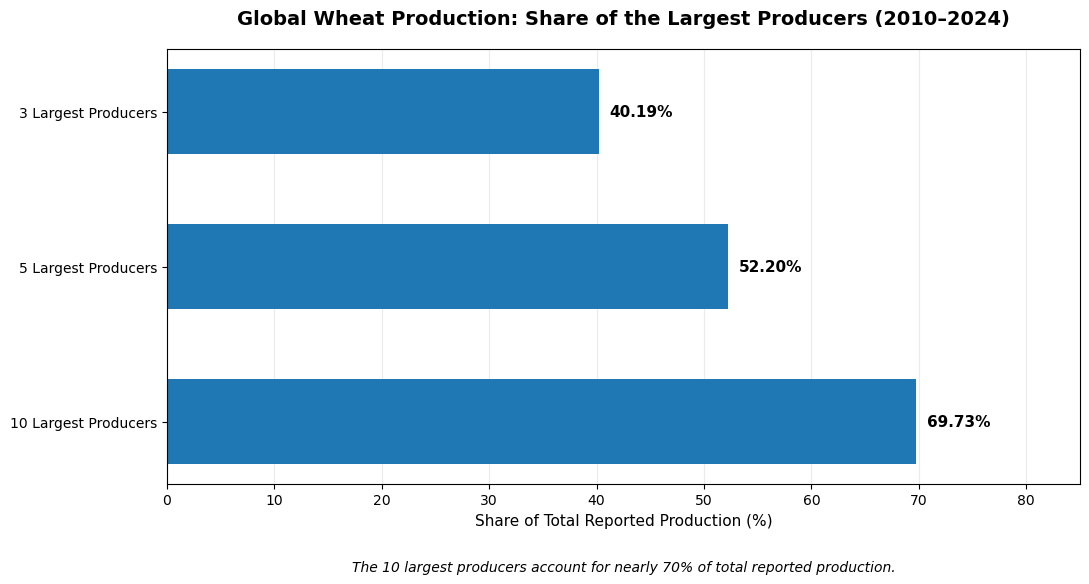

In [140]:
fig, ax = plt.subplots(figsize=(11, 6))

labels = [
    "3 Largest Producers",
    "5 Largest Producers",
    "10 Largest Producers"
]

bars = ax.barh(
    labels,
    concentration_data["global_share_pct"],
    height=0.55
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=8,
    fontsize=11,
    fontweight="bold"
)

ax.invert_yaxis()

ax.set_title(
    "Global Wheat Production: Share of the Largest Producers (2010–2024)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Share of Total Reported Production (%)", fontsize=11)
ax.set_xlim(0, 85)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

ax.text(
    0.5, -0.20,
    "The 10 largest producers account for nearly 70% of total reported production.",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    style="italic"
)

plt.tight_layout()
plt.show()

#### Key Finding

The 10 largest wheat-producing reporting areas accounted for 69.73% of total reported global wheat production between 2010 and 2024, highlighting the concentration of production among a relatively small group of major producers.

**Note:** Shares are calculated using cumulative reported wheat production from 2010 to 2024. Missing production values are excluded, and overlapping China reporting areas are excluded to avoid double counting.

### 8.3 Country-Level Production Trends

This section examines how wheat production has changed over time in the five largest producing areas between 2010 and 2024. Annual production trends are compared to identify differences in growth patterns and production fluctuations.

In [143]:
# Identify the top 5 wheat-producing countries

top_5_countries = (
    country_production.head(5)["area"].tolist()
)

# Prepare annual production trends for the top 5 countries

country_trends = (
    analysis_df[
        analysis_df["area"].isin(top_5_countries)
    ]
    .pivot_table(
        index="year",
        columns="area",
        values="production_value",
        aggfunc="sum"
    )
    / 1_000_000
)

print("Top 5 producers:", top_5_countries)
display(country_trends.head())

Top 5 producers: ['China', 'India', 'Russian Federation', 'United States of America', 'France']


area,China,France,India,Russian Federation,United States of America
year,,,,,
2010,115.186178,38.207431,80.8036,41.507581,60.062408
2011,117.414034,35.992794,86.8740,56.239994,54.418808
2012,121.030059,37.885742,94.8800,37.719640,61.677384
2013,121.930527,38.651472,93.5100,52.090797,58.104610
2014,126.215211,38.950202,95.8500,59.711382,55.147120


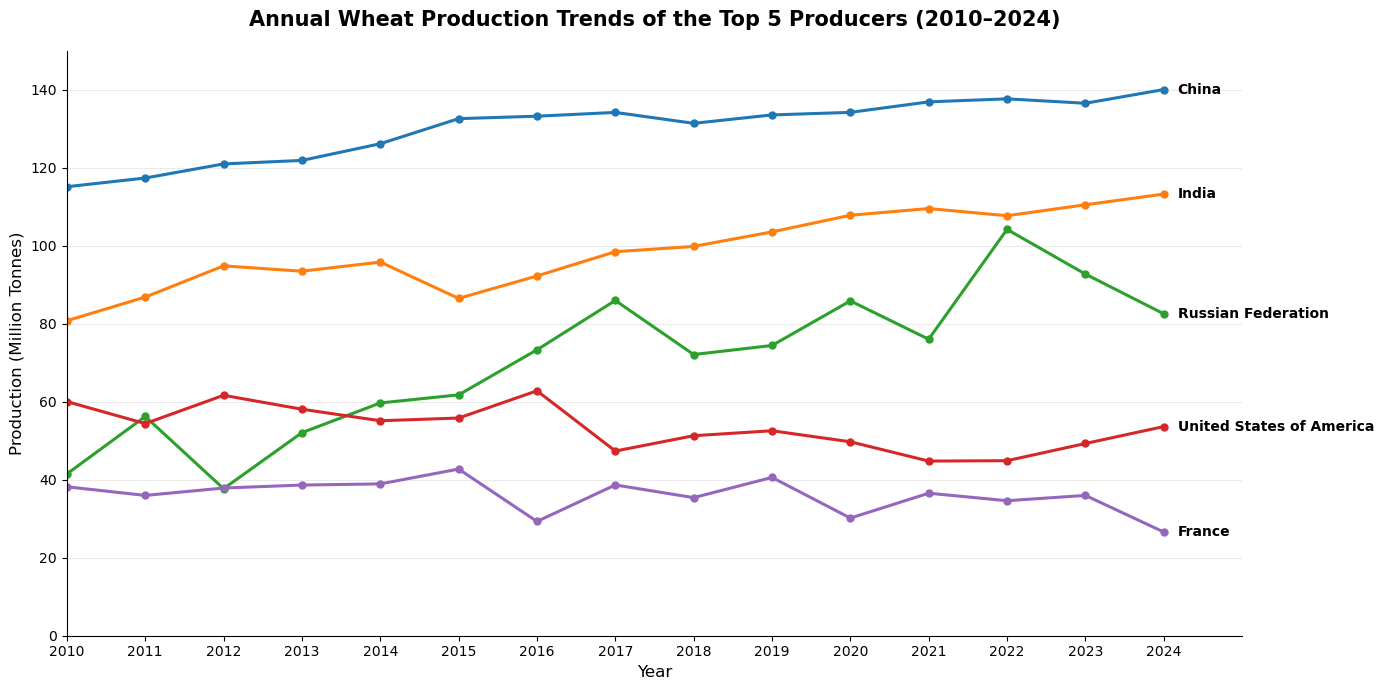

In [144]:
fig, ax = plt.subplots(figsize=(14, 7))

for country in top_5_countries:
    ax.plot(
        country_trends.index,
        country_trends[country],
        marker="o",
        linewidth=2.2,
        markersize=5
    )

    # Label at the final data point (2024)
    last_year = country_trends[country].last_valid_index()
    last_value = country_trends.loc[last_year, country]

    ax.annotate(
        country,
        xy=(last_year, last_value),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Annual Wheat Production Trends of the Top 5 Producers (2010–2024)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Production (Million Tonnes)", fontsize=12)

ax.set_xticks(country_trends.index)
ax.set_ylim(0, 150)
ax.set_xlim(2010, 2025)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


- China maintained the highest wheat production throughout the entire period, with a generally increasing trend.
- India showed consistent long-term growth, reaching approximately 113 million tonnes in 2024.
- Russian Federation experienced considerable annual fluctuations, with a notable production peak in 2022.
- Wheat production in the United States generally declined compared to its 2010 level, despite a partial recovery in recent years.
- France showed a fluctuating but relatively stable production pattern, with its lowest level recorded in 2024.

### 8.4 Changes in Global Wheat Production Leaders

This section compares the top 10 wheat-producing reporting areas in 2010 and 2024 to identify changes in global production rankings and shifts among the leading producers.

In [147]:
# Prepare production data for ranking comparison

ranking_data = (
    analysis_df[
        analysis_df["year"].isin([2010, 2024])
    ]
    .groupby(["area", "year"])["production_value"]
    .sum()
    .reset_index()
)

# Identify the Top 10 producers for each year

top_10_by_year = {
    year: (
        ranking_data[ranking_data["year"] == year]
        .nlargest(10, "production_value")
    )
    for year in [2010, 2024]
}

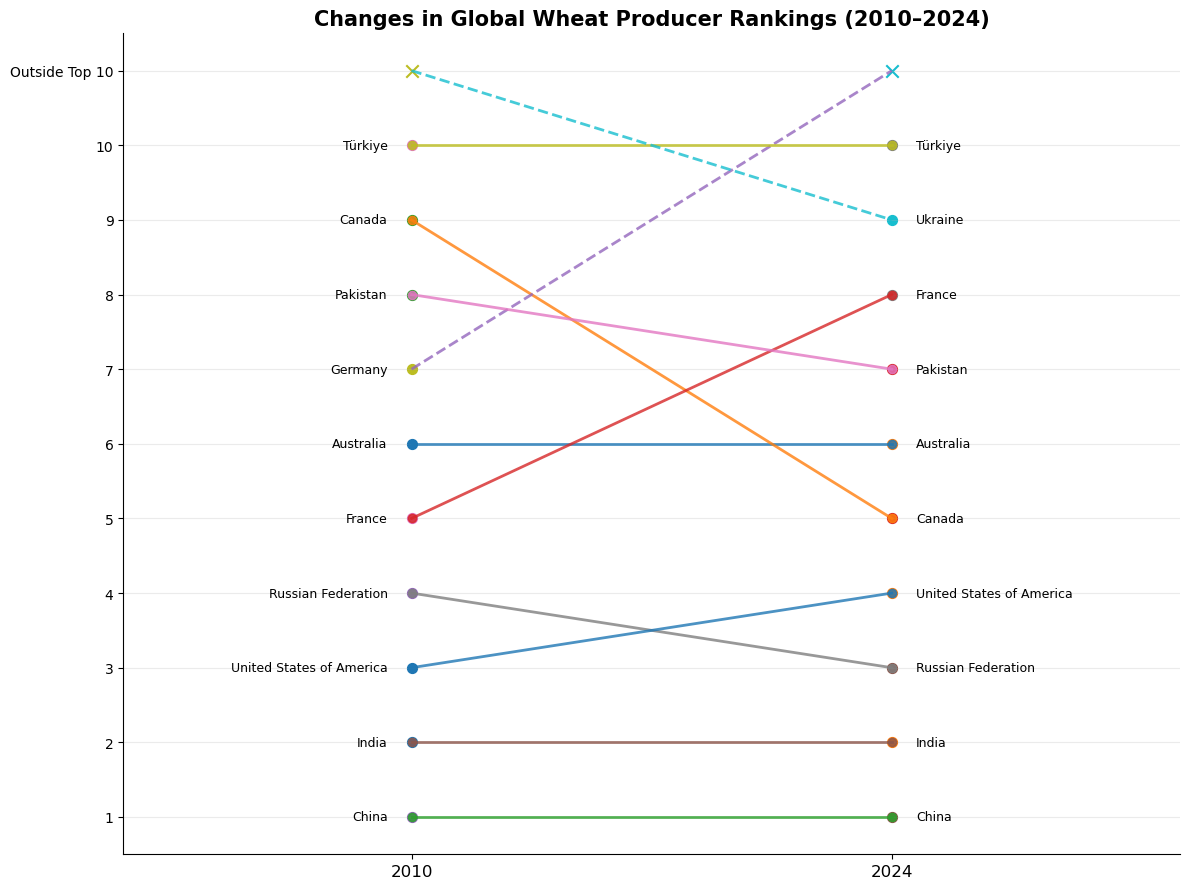

In [148]:
# Prepare ranking positions for 2010 and 2024

ranking_pivot = ranking_data.pivot(
    index="area",
    columns="year",
    values="production_value"
)

ranking_positions = pd.DataFrame(index=ranking_pivot.index)

for year in [2010, 2024]:
    ranking_positions[year] = (
        ranking_pivot[year]
        .rank(method="min", ascending=False)
    )

# Identify countries appearing in the Top 10 in either year

top_10_2010 = set(top_10_by_year[2010]["area"])
top_10_2024 = set(top_10_by_year[2024]["area"])

comparison_countries = sorted(top_10_2010 | top_10_2024)

slope_data = ranking_positions.loc[
    comparison_countries
].copy()

# Plot ranking changes

fig, ax = plt.subplots(figsize=(12, 9))

for country, row in slope_data.iterrows():

    rank_2010 = row[2010]
    rank_2024 = row[2024]

    if pd.isna(rank_2010) or rank_2010 > 10:
        rank_2010 = 11

    if pd.isna(rank_2024) or rank_2024 > 10:
        rank_2024 = 11

    if rank_2010 == 11 and rank_2024 == 11:
        continue

    ax.plot(
        [0, 1],
        [rank_2010, rank_2024],
        linestyle="--" if 11 in [rank_2010, rank_2024] else "-",
        marker="o" if 11 not in [rank_2010, rank_2024] else None,
        linewidth=2,
        alpha=0.8
    )

    if rank_2010 == 11:
        ax.scatter(0, 11, marker="x", s=80)
    else:
        ax.scatter(0, rank_2010, s=50)
        ax.text(
            -0.05, rank_2010, country,
            ha="right", va="center", fontsize=9
        )

    if rank_2024 == 11:
        ax.scatter(1, 11, marker="x", s=80)
    else:
        ax.scatter(1, rank_2024, s=50)
        ax.text(
            1.05, rank_2024, country,
            ha="left", va="center", fontsize=9
        )

ax.set_title(
    "Changes in Global Wheat Producer Rankings (2010–2024)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["2010", "2024"], fontsize=12)

ax.set_yticks(range(1, 12))
ax.set_yticklabels(
    [str(i) for i in range(1, 11)] + ["Outside Top 10"]
)

ax.set_xlim(-0.6, 1.6)
ax.grid(axis="y", alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

* China and India maintained their leading positions, ranking first and second in both 2010 and 2024.
* Canada recorded the most significant improvement among the top 10 producers, rising from 9th to 5th place.
* Ukraine entered the top 10 in 2024, while Germany dropped out of the top 10.
* Russian Federation moved up one position, from 4th to 3rd, while the United States declined from 3rd to 4th.
* France fell from 5th to 8th place, whereas Australia and Türkiye maintained their rankings.

# 9. Key Findings & Insights

The analysis of global wheat production between 2010 and 2024 revealed several important findings:

* Global production growth: Reported wheat production increased from 653.7 million tonnes in 2010 to 798.5 million tonnes in 2024, representing an overall increase of approximately 22.1%. Production reached its highest level in 2022 at 808.0 million tonnes.
* Annual fluctuations: Global production did not increase consistently. The strongest annual growth occurred in 2013 (+8.13%), while the largest decline was recorded in 2012 (-5.44%).
* Leading producers: China and India maintained the first and second positions throughout the period. Russia, the United States, France, Canada, and Australia were also among the major wheat producers.
* Production concentration: The ten largest producers accounted for 69.73% of total reported production between 2010 and 2024, demonstrating that global wheat production is concentrated among a relatively small number of countries.
* Changes in country rankings: Canada improved its position from ninth to fifth, while Ukraine entered the top ten. Germany, previously ranked seventh, moved outside the top ten by 2024.

The findings indicate that global wheat production expanded over the period, but production levels and growth patterns varied considerably across countries and years.

In [188]:
analysis_df.to_csv(
    "../data/processed/global_wheat_production_clean.csv",
    index=False
)

# Compare country production rankings in 2010 and 2024

ranking_comparison = (
    analysis_df[
        analysis_df["year"].isin([2010, 2024])
    ]
    .groupby(["area", "year"])["production_value"]
    .sum()
    .reset_index()
)

ranking_comparison["rank"] = (
    ranking_comparison.groupby("year")["production_value"]
    .rank(method="min", ascending=False)
    .astype(int)
)

ranking_comparison = (
    ranking_comparison
    .pivot(index="area", columns="year", values="rank")
    .reset_index()
)

ranking_comparison.columns.name = None
ranking_comparison.columns = ["Country", "2010 Rank", "2024 Rank"]

ranking_comparison = ranking_comparison[
    (ranking_comparison["2010 Rank"] <= 10) |
    (ranking_comparison["2024 Rank"] <= 10)
]

ranking_comparison = ranking_comparison.sort_values(
    "2024 Rank", na_position="last"
)

display(ranking_comparison)
ranking_comparison.to_csv(
    "../data/processed/country_ranking_comparison.csv",
    index=False
)

,Country,2010 Rank,2024 Rank
23,China,1.0,1.0
45,India,2.0,2.0
94,Russian Federation,4.0,3.0
118,United States of America,3.0,4.0
20,Canada,9.0,5.0
6,Australia,6.0,6.0
84,Pakistan,8.0,7.0
38,France,5.0,8.0
114,Ukraine,11.0,9.0
112,Türkiye,10.0,10.0


### Key Findings: Changes in Country Rankings (2010–2024)

The comparison of global wheat production rankings reveals several notable changes between 2010 and 2024:

- **Canada** improved from 9th to 5th place, recording the strongest upward movement among the countries analyzed.
- **Ukraine** entered the Top 10, moving from 11th to 9th place.
- **Germany** declined from 7th to 12th place, falling outside the Top 10.
- **Russian Federation** improved from 4th to 3rd place.
- **France** dropped from 5th to 8th place.
- **Türkiye** maintained its 10th position in both years.

These changes highlight shifts in the geographical distribution of global wheat production over the study period.